# Process-grid speedup — `16x1` vs `4x4`

How much does the **process-grid layout** cost or buy you, at a fixed GPU count?

Every case under `results/<root>/cases/<routine>/<dtype>/<grid>/*.json` is one
timed solve. `16x1` and `4x4` both use 16 GPUs on 4 nodes, so a ratio between
them isolates the layout: same routine, same dtype, same matrix dimension.

Loading follows [`benchmark/cusolvermp/plot.py`](benchmark/cusolvermp/plot.py) —
read every case JSON, keep `status == "passed"`, use `warm_median_seconds`.

**Speedup convention** — `speedup = baseline_seconds / candidate_seconds`, with
`16x1` the baseline. So `1.8` means `4x4` is 1.8x faster; `0.6` means `4x4` is
slower.

Two comparisons, because two questions:

| Mode | Compares | Answers |
|---|---|---|
| `matched_tile` | same `(N, T_A)` in both grids | pure layout effect at a fixed tile |
| `best_tile` | fastest `T_A` per grid, per `N` | what you get if you tune `T_A` for each layout |

Only stdlib + `matplotlib` are required.


In [82]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import NullFormatter


def find_repo_root(start=None):
    """Locate the jaxmg_benchmark checkout that contains the results tree.

    Args:
        start: Directory to search upwards from; defaults to the working
            directory, which is the notebook's own directory in VS Code.

    Returns:
        The first ancestor holding ``benchmark/cusolvermp``, else ``start``.
    """
    here = Path(start or Path.cwd()).resolve()
    for candidate in (here, *here.parents):
        if (candidate / "benchmark" / "cusolvermp").is_dir():
            return candidate
        if (candidate / "jaxmg_benchmark" / "benchmark" / "cusolvermp").is_dir():
            return candidate / "jaxmg_benchmark"
    return here


REPO_ROOT = find_repo_root()

# --- knobs -------------------------------------------------------------------
RESULT_ROOT = REPO_ROOT / "results" / "rusty_h100_4gpu"
BASELINE_GRID = "16x1"
CANDIDATE_GRID = "4x4"
TIME_FIELD = "warm_median_seconds"  # warm_min_seconds / warm_max_seconds / cold_seconds also exist
# -----------------------------------------------------------------------------


def available_result_roots(results_dir=None):
    """List every directory that holds a ``cases`` tree.

    Args:
        results_dir: Root of the results tree; defaults to ``REPO_ROOT/results``.

    Returns:
        Sorted result roots that can be assigned to ``RESULT_ROOT``.
    """
    results_dir = Path(results_dir or REPO_ROOT / "results")
    found = {path.parent for pattern in ("*/cases", "*/*/cases")
             for path in results_dir.glob(pattern)}
    return sorted(found)


print(f"repo root:   {REPO_ROOT}")
print(f"result root: {RESULT_ROOT}  (exists={RESULT_ROOT.exists()})")
print("\nother result roots you can point RESULT_ROOT at:")
for root in available_result_roots():
    print(f"  {root.relative_to(REPO_ROOT)}")


repo root:   /mnt/home/rwiersema/jaxmg/jaxmg_benchmark
result root: /mnt/home/rwiersema/jaxmg/jaxmg_benchmark/results/rusty_h100_4gpu  (exists=True)

other result roots you can point RESULT_ROOT at:
  results/old/rusty
  results/old/rusty_ib_gdroff
  results/old/rusty_test
  results/old/rusty_test_old
  results/rusty_h100_4gpu
  results/rusty_h200_8gpu


### Figure style

Every figure below is drawn in one journal style: STIX text and math, an 8/7/6 pt
type scale, in-facing major and minor ticks, and Type-42 fonts so the PDF keeps
editable text. `COL1` / `COL2` are the single- and double-column widths, so a
figure is sized for the page rather than resized after the fact.

In [83]:
# --- required journal style --------------------------------------------------
# Set once here and obeyed by every figure below, so the plots drop straight
# into a manuscript: STIX text and math, an 8/7/6 pt type scale, in-facing major
# and minor ticks, and Type-42 fonts so PDF/PS output keeps editable text.
import matplotlib

matplotlib.rcParams["mathtext.fontset"] = "stix"
matplotlib.rcParams["font.family"] = "STIXGeneral"
matplotlib.rcParams.update(
    {
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "legend.fontsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        # --- journal-safe output + house style ------------------------------
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "axes.linewidth": 0.8,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.minor.visible": True,
        "ytick.minor.visible": True,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.minor.size": 1.5,
        "ytick.minor.size": 1.5,
        "legend.frameon": False,
    }
)

# --- journal column widths (inches) ------------------------------------------
COL1 = 3.375  # single column  (8.6 cm)
COL2 = 6.75  # double column  (17.1 cm)

# --- one type scale, used verbatim by every normal figure --------------------
FS_LABEL = 8  # axis labels, sup-labels, subplot titles, colorbar labels
FS_TICK = 7  # tick labels, legends, panel letters, in-plot callouts
FS_SMALL = 6  # insets, dense in-panel text (fit legend, colorbar ticks)

# seaborn "colorblind" palette
COLORBLIND = [
    "#029E73",
    "#00008C",
    "#AD2E24",
    "#F58A07",
    "#F3B61F",
    "#620088",
    "#FBAFE4",
    "#949494",
    "#ECE133",
    "#56B4E9",
]

FIGDIR = REPO_ROOT / "figures"
FIGDIR.mkdir(exist_ok=True)

print(f"journal style applied; saved figures go to {FIGDIR}")

journal style applied; saved figures go to /mnt/home/rwiersema/jaxmg/jaxmg_benchmark/figures


## 1. Load the case records

`load_records` mirrors the reader in `plot.py`, plus a derived `grid` key
(`"{process_rows}x{process_cols}"`) so records can be filtered without touching
the directory layout. Failed cases carry only `case_id`, shape and `returncode`,
so they are kept separately and used for coverage in §6.


In [84]:
def load_records(result_root=None, include_failed=False):
    """Read every case JSON under a result root.

    Args:
        result_root: Result root holding a ``cases`` directory; defaults to
            ``RESULT_ROOT``.
        include_failed: Keep records whose ``status`` is not ``"passed"``.

    Returns:
        Case records, each with added ``grid`` and ``result_path`` keys.

    Raises:
        FileNotFoundError: If the root has no ``cases`` directory.
    """
    cases_dir = Path(result_root or RESULT_ROOT) / "cases"
    if not cases_dir.is_dir():
        raise FileNotFoundError(f"no cases directory under {cases_dir.parent}")
    records = []
    for path in sorted(cases_dir.rglob("*.json")):
        record = json.loads(path.read_text(encoding="utf-8"))
        if record.get("status") != "passed" and not include_failed:
            continue
        record["grid"] = f"{record['process_rows']}x{record['process_cols']}"
        # Records written before the backend axis existed are all cuSOLVERMp.
        record["backend"] = record.get("backend", "cusolvermp")
        record["result_path"] = str(path)
        records.append(record)
    return records


RECORDS = load_records()
ALL_RECORDS = load_records(include_failed=True)

ROUTINES = sorted({record["routine"] for record in ALL_RECORDS})
DTYPES = sorted({record["dtype"] for record in ALL_RECORDS})
GRIDS = sorted({record["grid"] for record in ALL_RECORDS})
TILES = sorted({record["tile_size"] for record in ALL_RECORDS})

print(f"{len(RECORDS)} passed / {len(ALL_RECORDS)} total case records")
print(f"routines: {ROUTINES}")
print(f"backends: {sorted({record['backend'] for record in ALL_RECORDS})}")
print(f"dtypes:   {DTYPES}")
print(f"grids:    {GRIDS}")
print(f"tiles:    {TILES}")


1710 passed / 2386 total case records
routines: ['gesvd', 'lu_solve', 'potrs', 'syevd']
backends: ['cusolvermp', 'jax']
dtypes:   ['complex128', 'complex64', 'float32', 'float64']
grids:    ['16x1', '1x1', '4x4']
tiles:    [0, 256, 512, 1024, 2048, 4096]


## 2. Speedup tables

`case_times` reduces the records to `{(matrix_size, tile_size): seconds}` for one
routine / dtype / grid. `speedup_rows` then joins the two grids on whatever they
share — exact `(N, T_A)` pairs in `matched_tile` mode, exact `N` in `best_tile`
mode. Sizes that only one grid completed are dropped from the join and reported
by `coverage_rows` in §6 instead.

`summarize` reports the **geometric mean**, which is the right average for
ratios: it treats a 2x speedup and a 2x slowdown as equal and opposite, and does
not let one huge ratio dominate.


In [85]:
def case_times(routine, dtype, grid, records=None, time_field=None):
    """Collect timings for one routine, dtype, and grid.

    Args:
        routine: Routine name, e.g. ``"potrs"``.
        dtype: Element type, e.g. ``"float64"``.
        grid: Process grid string, e.g. ``"4x4"``.
        records: Passing records to read; defaults to ``RECORDS``.
        time_field: Record field holding the timing; defaults to ``TIME_FIELD``.

    Returns:
        Mapping of ``(matrix_size, tile_size)`` to seconds. Repeated cases keep
        the fastest run.
    """
    records = RECORDS if records is None else records
    time_field = time_field or TIME_FIELD
    times = {}
    for record in records:
        if (record["routine"], record["dtype"], record["grid"]) != (routine, dtype, grid):
            continue
        value = record.get(time_field)
        if isinstance(value, list):  # cold_seconds is a list
            value = min(value)
        if value is None:
            continue
        key = (record["matrix_size"], record["tile_size"])
        if key not in times or value < times[key]:
            times[key] = value
    return times


def best_per_size(times):
    """Reduce per-tile timings to the fastest tile for each matrix size.

    Args:
        times: Mapping of ``(matrix_size, tile_size)`` to seconds.

    Returns:
        Mapping of ``matrix_size`` to ``(tile_size, seconds)``.
    """
    best = {}
    for (size, tile), seconds in sorted(times.items()):
        if size not in best or seconds < best[size][1]:
            best[size] = (tile, seconds)
    return best


def speedup_rows(routine, dtype, mode="best_tile", baseline=None, candidate=None,
                 min_size=0, records=None, time_field=None):
    """Join two grids and compute ``baseline / candidate`` timing ratios.

    Args:
        routine: Routine name.
        dtype: Element type.
        mode: ``"best_tile"`` compares the fastest tile per grid at each matrix
            size; ``"matched_tile"`` compares identical ``(N, T_A)`` cases.
        baseline: Denominator grid of the speedup; defaults to ``BASELINE_GRID``.
        candidate: Grid being scored; defaults to ``CANDIDATE_GRID``.
        min_size: Drop matrix sizes below this dimension.
        records: Passing records to read; defaults to ``RECORDS``.
        time_field: Record field holding the timing; defaults to ``TIME_FIELD``.

    Returns:
        Rows sorted by matrix size, each holding both timings and ``speedup``
        (greater than one means the candidate grid is faster).

    Raises:
        ValueError: If ``mode`` is not a supported comparison.
    """
    baseline = baseline or BASELINE_GRID
    candidate = candidate or CANDIDATE_GRID
    base_times = case_times(routine, dtype, baseline, records, time_field)
    cand_times = case_times(routine, dtype, candidate, records, time_field)

    rows = []
    if mode == "matched_tile":
        for size, tile in sorted(set(base_times) & set(cand_times)):
            if size < min_size:
                continue
            rows.append({
                "matrix_size": size,
                "tile_size": tile,
                f"{baseline}_seconds": base_times[(size, tile)],
                f"{candidate}_seconds": cand_times[(size, tile)],
                "speedup": base_times[(size, tile)] / cand_times[(size, tile)],
            })
    elif mode == "best_tile":
        base_best = best_per_size(base_times)
        cand_best = best_per_size(cand_times)
        for size in sorted(set(base_best) & set(cand_best)):
            if size < min_size:
                continue
            base_tile, base_seconds = base_best[size]
            cand_tile, cand_seconds = cand_best[size]
            rows.append({
                "matrix_size": size,
                f"{baseline}_tile": base_tile,
                f"{baseline}_seconds": base_seconds,
                f"{candidate}_tile": cand_tile,
                f"{candidate}_seconds": cand_seconds,
                "speedup": base_seconds / cand_seconds,
            })
    else:
        raise ValueError(f"unknown mode {mode!r}; use 'best_tile' or 'matched_tile'")
    return rows


def summarize(rows, key="speedup"):
    """Reduce speedup rows to geometric-mean, median, and extreme ratios.

    Args:
        rows: Rows produced by :func:`speedup_rows`.
        key: Row field to summarize.

    Returns:
        Summary statistics, or an empty mapping when ``rows`` is empty.
    """
    values = sorted(row[key] for row in rows)
    if not values:
        return {}
    geomean = math.exp(sum(math.log(value) for value in values) / len(values))
    middle = len(values) // 2
    median = values[middle] if len(values) % 2 else 0.5 * (values[middle - 1] + values[middle])
    return {
        "cases": len(values),
        "geomean": geomean,
        "median": median,
        "min": values[0],
        "max": values[-1],
        "candidate_wins": sum(value > 1.0 for value in values),
    }


### Printing helpers

Plain-text tables so the notebook runs on any kernel. `to_dataframe` is there if
you have pandas and want to sort, pivot, or write CSV.


In [86]:
SPEEDUP_COLUMNS = ("speedup", "geomean", "median", "min", "max", "at_largest_N")


def _format_cell(column, value):
    """Render one table cell.

    Args:
        column: Column name, used to pick ratio formatting.
        value: Cell value.

    Returns:
        The formatted text.
    """
    if value is None:
        return "-"
    if column in SPEEDUP_COLUMNS and isinstance(value, float):
        return f"{value:.2f}x"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, int):
        return f"{value:,}"
    if isinstance(value, float):
        return f"{value:,.4g}"
    return str(value)


def print_table(rows, columns=None, title=None):
    """Print rows as an aligned text table.

    Args:
        rows: Sequence of mappings sharing the same keys.
        columns: Column order; defaults to the first row's key order.
        title: Optional heading printed above the table.
    """
    if title:
        print(title)
    if not rows:
        print("  (no rows)")
        return
    columns = list(columns or rows[0].keys())
    cells = [[_format_cell(column, row.get(column)) for column in columns] for row in rows]
    widths = [max(len(column), *(len(row[index]) for row in cells))
              for index, column in enumerate(columns)]
    header = "  ".join(column.rjust(width) for column, width in zip(columns, widths))
    print(header)
    print("  ".join("-" * width for width in widths))
    for row in cells:
        print("  ".join(cell.rjust(width) for cell, width in zip(row, widths)))


def print_summary(rows, label="", unit="cases"):
    """Print the geometric-mean summary of a speedup table.

    Args:
        rows: Rows produced by :func:`speedup_rows`.
        label: Text prefix identifying the comparison.
        unit: Noun for what each row counts, used in the win tally.
    """
    stats = summarize(rows)
    if not stats:
        print(f"{label}no comparable cases")
        return
    print(
        f"{label}geomean {stats['geomean']:.2f}x  median {stats['median']:.2f}x  "
        f"range {stats['min']:.2f}x-{stats['max']:.2f}x  "
        f"({stats['candidate_wins']}/{stats['cases']} {unit} favour {CANDIDATE_GRID})"
    )


def to_dataframe(rows):
    """Convert rows to a pandas DataFrame when pandas is installed.

    Args:
        rows: Sequence of mappings.

    Returns:
        A DataFrame, or ``None`` if pandas is unavailable.
    """
    try:
        import pandas as pd
    except ImportError:
        print("pandas is not installed in this kernel; use print_table instead")
        return None
    return pd.DataFrame(rows)


## 3. One routine, one dtype

Set `ROUTINE` and `DTYPE` and re-run this section. This is the main knob.


In [87]:
ROUTINE = "potrs"
DTYPE = "float64"

best_rows = speedup_rows(ROUTINE, DTYPE, mode="best_tile")
print_table(best_rows, title=f"{ROUTINE} / {DTYPE} — fastest tile per grid "
                             f"({BASELINE_GRID} -> {CANDIDATE_GRID})\n")
print()
print_summary(best_rows, label=f"{ROUTINE}/{DTYPE} best-tile: ", unit="sizes")


potrs / float64 — fastest tile per grid (16x1 -> 4x4)

matrix_size  16x1_tile  16x1_seconds  4x4_tile  4x4_seconds  speedup
-----------  ---------  ------------  --------  -----------  -------
      4,096        256        0.2701     1,024       0.1807    1.49x
      8,192        512        0.3359     2,048       0.1989    1.69x
     16,384      1,024        0.4611     1,024       0.2448    1.88x
     32,768      2,048        0.9142     1,024       0.3922    2.33x
     49,152      1,024         2.725     1,024       0.6561    4.15x
     65,536      4,096         2.939     1,024        1.022    2.88x
     98,304      2,048         8.949     1,024        2.107    4.25x
    131,072      2,048          14.1     1,024        3.594    3.92x
    196,608      2,048         33.84     1,024        8.693    3.89x
    262,144      4,096         57.98     2,048        17.01    3.41x
    327,680      4,096         100.5     2,048        28.71    3.50x
    393,216      2,048         151.7     2,048  

The `best_tile` table can compare two different tile sizes, so part of the ratio
is tile tuning rather than layout. `matched_tile` removes that: same `N`, same
`T_A`, only the grid differs.


In [88]:
matched_rows = speedup_rows(ROUTINE, DTYPE, mode="matched_tile")
print_table(matched_rows, title=f"{ROUTINE} / {DTYPE} — matched (N, T_A)\n")
print()
print_summary(matched_rows, label=f"{ROUTINE}/{DTYPE} matched-tile: ", unit="cases")

# Large matrices only — where the layout actually matters.
large_rows = speedup_rows(ROUTINE, DTYPE, mode="best_tile", min_size=65536)
print()
print_summary(large_rows, label=f"{ROUTINE}/{DTYPE} best-tile, N >= 65536: ", unit="sizes")


potrs / float64 — matched (N, T_A)

matrix_size  tile_size  16x1_seconds  4x4_seconds  speedup
-----------  ---------  ------------  -----------  -------
      4,096        256        0.2701       0.1994    1.35x
      8,192        256         0.374       0.2126    1.76x
      8,192        512        0.3359       0.1994    1.69x
     16,384        256        0.7322       0.2642    2.77x
     16,384        512        0.6399       0.2484    2.58x
     16,384      1,024        0.4611       0.2448    1.88x
     32,768        256         2.163       0.4463    4.85x
     32,768        512         1.808       0.4038    4.48x
     32,768      1,024         1.269       0.3922    3.24x
     32,768      2,048        0.9142       0.4205    2.17x
     49,152        256         4.744       0.7774    6.10x
     49,152        512         3.829       0.6718    5.70x
     49,152      1,024         2.725       0.6561    4.15x
     65,536        256          7.81        1.282    6.09x
     65,536        5

## 4. Plots

Two series (`16x1`, `4x4`) get the first two categorical hues; tile size is an
*ordered* quantity, so the per-tile chart uses one blue ramp light-to-dark rather
than unrelated hues. The speedup chart is diverging around parity: blue points
sit above `1.0` (candidate faster), red below.


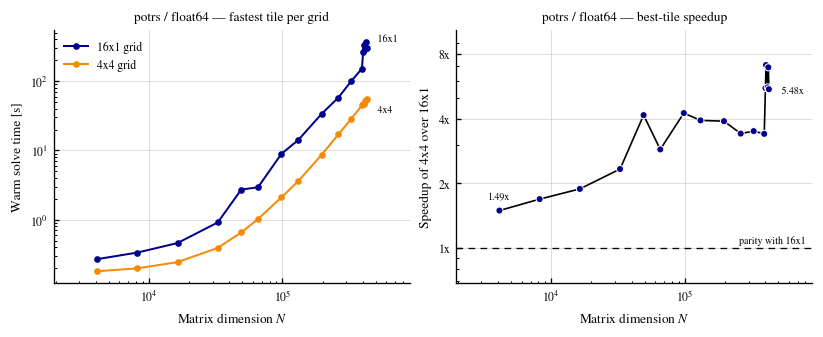

In [89]:
# Palette: the two grids take categorical hues from the "colorblind" ramp; tile
# size is an *ordered* quantity, so the per-tile chart uses one blue ramp
# light-to-dark rather than unrelated hues; the speedup charts are diverging
# around parity, with the palette's navy for "faster" and red for "slower".
SERIES_COLORS = {"baseline": COLORBLIND[1], "candidate": COLORBLIND[3],
                 "native": COLORBLIND[0]}
# The single-GPU JAX reference the distributed timings are measured against.
# The suite records it under backend "jax", always on a 1x1 grid.
NATIVE_GRID = "1x1"
TILE_RAMP = ("#9ecae1", "#6baed6", "#3182bd", "#08519c", "#08306b")
FASTER, SLOWER, NEUTRAL = COLORBLIND[1], COLORBLIND[2], "#f0efec"
# Chart chrome is plain black ink on white; the grid is a light tint so it stays
# behind the data now that the style draws in-facing major and minor ticks.
INK = AXIS = "#000000"
GRIDLINE = "#cccccc"
SURFACE = "#ffffff"
# Diverging: red = candidate slower, near-white = parity, navy = candidate faster.
# The two stops either side of the midpoint stay light enough that mid-range
# cells still take dark ink from ``contrast_ink``.
DIVERGING = mcolors.LinearSegmentedColormap.from_list(
    "speedup", ["#5c1813", SLOWER, "#e8b3ad", NEUTRAL, "#b6bce8", "#4b52b8", FASTER]
)


def contrast_ink(color):
    """Pick primary or inverted ink so text stays legible on a filled cell.

    Args:
        color: Any matplotlib color for the fill behind the text.

    Returns:
        White for dark fills, the primary ink otherwise.
    """
    channels = [value / 12.92 if value <= 0.04045 else ((value + 0.055) / 1.055) ** 2.4
                for value in mcolors.to_rgb(color)]
    luminance = 0.2126 * channels[0] + 0.7152 * channels[1] + 0.0722 * channels[2]
    return "#ffffff" if luminance < 0.35 else INK


# Tick ladders from coarse to fine; the first one that puts enough ticks inside
# the data range wins, so a 0.9x-1.1x chart is not left with a single "1x" line.
SPEEDUP_TICK_LADDERS = (
    (0.125, 0.25, 0.5, 1, 2, 4, 8, 16, 32),
    (0.5, 0.7, 1, 1.5, 2, 3, 4, 6, 8),
    (0.8, 0.9, 1, 1.1, 1.25, 1.5, 1.75, 2),
    (0.9, 0.95, 1, 1.05, 1.1, 1.2, 1.3),
)


def set_speedup_scale(axis, values):
    """Put the speedup axis on a log scale with ratio ticks around parity.

    Args:
        axis: Matplotlib axis to rescale.
        values: Speedup values that must stay in view; parity is always shown.
    """
    low = min(min(values), 1.0) / 1.45
    high = max(max(values), 1.0) * 1.45
    ticks = [1.0]
    for ladder in SPEEDUP_TICK_LADDERS:
        inside = [tick for tick in ladder if low <= tick <= high]
        if len(inside) >= 4:
            ticks = inside
            break
    axis.set_yscale("log")
    axis.set_yticks(ticks)
    axis.set_yticklabels([f"{tick:g}x" for tick in ticks])
    axis.yaxis.set_minor_formatter(NullFormatter())
    axis.set_ylim(low, high)


def style_axis(axis, xlabel, ylabel, title):
    """Apply the recessive grid, spine, and label styling used by every figure.

    Args:
        axis: Matplotlib axis to style.
        xlabel: Text for the x axis.
        ylabel: Text for the y axis.
        title: Figure title.
    """
    axis.set_xlabel(xlabel, color=INK, fontsize=FS_LABEL)
    axis.set_ylabel(ylabel, color=INK, fontsize=FS_LABEL)
    axis.set_title(title, color=INK, loc="center", fontsize=FS_LABEL)
    # One light major grid only; the style already draws minor ticks, so a
    # second dashed grid layer would just add noise at 8 pt.
    axis.grid(which="major", color=GRIDLINE, linewidth=0.4, zorder=0)
    axis.set_axisbelow(True)
    axis.tick_params(colors=INK, labelsize=FS_TICK)
    for side, spine in axis.spines.items():
        spine.set_visible(side in ("left", "bottom"))
        spine.set_color(AXIS)


def plot_time_comparison(routine, dtype, axis=None, min_size=0, common_only=True):
    """Plot warm solve time against matrix dimension for both grids.

    Args:
        routine: Routine name.
        dtype: Element type.
        axis: Existing axis to draw on; a new figure is made when omitted.
        min_size: Drop matrix sizes below this dimension.
        common_only: Restrict to matrix sizes both grids completed, matching the
            join used by the speedup tables. Set to ``False`` to show how far
            each layout reached on its own.

    Returns:
        The axis that was drawn on.
    """
    if axis is None:
        _, axis = plt.subplots(figsize=(COL1, COL1 * 0.78), constrained_layout=True)
    best_by_grid = {grid: best_per_size(case_times(routine, dtype, grid))
                    for grid in (BASELINE_GRID, CANDIDATE_GRID)}
    shared = set.intersection(*(set(best) for best in best_by_grid.values()))
    for grid, slot, nudge in ((BASELINE_GRID, "baseline", 6), (CANDIDATE_GRID, "candidate", -6)):
        best = best_by_grid[grid]
        sizes = sorted(size for size in best
                       if size >= min_size and (size in shared or not common_only))
        if not sizes:
            continue
        seconds = [best[size][1] for size in sizes]
        axis.plot(sizes, seconds, marker="o", markersize=3,
                  color=SERIES_COLORS[slot], label=f"{grid} grid", zorder=3)
        # Staggered vertically so the labels stay apart where the curves meet.
        axis.annotate(f" {grid}", (sizes[-1], seconds[-1]), textcoords="offset points",
                      xytext=(5, nudge), va="center", fontsize=FS_SMALL, color=INK,
                      annotation_clip=False)
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.margins(x=0.16)
    style_axis(axis, r"Matrix dimension $N$", "Warm solve time [s]",
               f"{routine} / {dtype} — fastest tile per grid")
    axis.legend(labelcolor=INK, fontsize=FS_TICK, loc="upper left")
    return axis


def plot_speedup(routine, dtype, axis=None, min_size=0):
    """Plot the best-tile grid speedup against matrix dimension.

    Args:
        routine: Routine name.
        dtype: Element type.
        axis: Existing axis to draw on; a new figure is made when omitted.
        min_size: Drop matrix sizes below this dimension.

    Returns:
        The axis that was drawn on.
    """
    if axis is None:
        _, axis = plt.subplots(figsize=(COL1, COL1 * 0.78), constrained_layout=True)
    rows = speedup_rows(routine, dtype, mode="best_tile", min_size=min_size)
    sizes = [row["matrix_size"] for row in rows]
    speedups = [row["speedup"] for row in rows]

    axis.axhline(1.0, color=AXIS, linewidth=0.8, linestyle=(0, (5, 4)), zorder=2)
    axis.annotate(f"parity with {BASELINE_GRID}", (1.0, 1.0), xycoords=("axes fraction", "data"),
                  textcoords="offset points", xytext=(-4, 3), ha="right", fontsize=FS_SMALL,
                  color=INK)
    if sizes:
        axis.plot(sizes, speedups, linewidth=1.0, color=INK, zorder=3)
        axis.scatter(sizes, speedups, s=18, zorder=4, linewidths=0.6, edgecolors=SURFACE,
                     color=[FASTER if value > 1.0 else SLOWER for value in speedups])
        # Label both ends, plus the extreme when it is far enough along the log
        # x axis from either end that the text will not collide.
        axis.annotate(f"{speedups[0]:.2f}x", (sizes[0], speedups[0]),
                      textcoords="offset points", xytext=(0, 7), ha="center",
                      fontsize=FS_SMALL, color=INK)
        axis.annotate(f" {speedups[-1]:.2f}x", (sizes[-1], speedups[-1]),
                      textcoords="offset points", xytext=(6, -2), ha="left",
                      fontsize=FS_SMALL, color=INK, annotation_clip=False)
        extreme = max(range(len(speedups)), key=lambda index: abs(math.log(speedups[index])))
        span = math.log10(sizes[-1] / sizes[0]) or 1.0
        if all(abs(math.log10(sizes[extreme] / sizes[end])) > 0.12 * span for end in (0, -1)):
            axis.annotate(f"{speedups[extreme]:.2f}x", (sizes[extreme], speedups[extreme]),
                          textcoords="offset points", xytext=(0, 7), ha="center",
                          fontsize=FS_SMALL, color=INK)
        set_speedup_scale(axis, speedups)
    axis.set_xscale("log")
    axis.margins(x=0.16)
    style_axis(axis, r"Matrix dimension $N$", f"Speedup of {CANDIDATE_GRID} over {BASELINE_GRID}",
               f"{routine} / {dtype} — best-tile speedup")
    return axis


figure, (left, right) = plt.subplots(1, 2, figsize=(COL2, COL2 * 0.40),
                                     constrained_layout=True)
plot_time_comparison(ROUTINE, DTYPE, axis=left)
plot_speedup(ROUTINE, DTYPE, axis=right)
plt.show()

### Speedup per tile size

One line per `T_A`, so you can see whether the layout verdict depends on the
tile. Lines that cross `1.0` mean the answer changes with `N`.


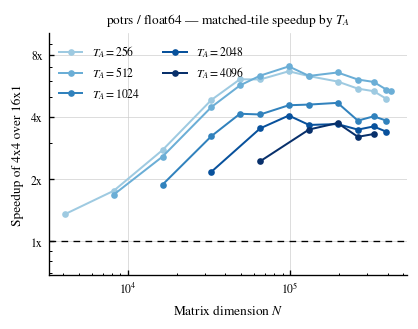

In [90]:
def plot_speedup_by_tile(routine, dtype, axis=None, min_size=0):
    """Plot matched-tile speedup with one line per tile size.

    Args:
        routine: Routine name.
        dtype: Element type.
        axis: Existing axis to draw on; a new figure is made when omitted.
        min_size: Drop matrix sizes below this dimension.

    Returns:
        The axis that was drawn on.
    """
    if axis is None:
        _, axis = plt.subplots(figsize=(COL1, COL1 * 0.78), constrained_layout=True)
    rows = speedup_rows(routine, dtype, mode="matched_tile", min_size=min_size)
    tiles = sorted({row["tile_size"] for row in rows})
    axis.axhline(1.0, color=AXIS, linewidth=0.8, linestyle=(0, (5, 4)), zorder=2)
    for index, tile in enumerate(tiles):
        selected = sorted((row for row in rows if row["tile_size"] == tile),
                          key=lambda row: row["matrix_size"])
        axis.plot([row["matrix_size"] for row in selected],
                  [row["speedup"] for row in selected],
                  marker="o", markersize=3,
                  color=TILE_RAMP[index % len(TILE_RAMP)],
                  label=rf"$T_A={tile}$", zorder=3)
    axis.set_xscale("log")
    if rows:
        set_speedup_scale(axis, [row["speedup"] for row in rows])
    style_axis(axis, r"Matrix dimension $N$",
               f"Speedup of {CANDIDATE_GRID} over {BASELINE_GRID}",
               f"{routine} / {dtype} — matched-tile speedup by $T_A$")
    # Upper left: the speedup climbs with N, so that corner is the empty one.
    axis.legend(labelcolor=INK, fontsize=FS_TICK, ncols=2, loc="upper left")
    return axis


plot_speedup_by_tile(ROUTINE, DTYPE)
plt.show()

## 5. Every routine and dtype at once

`sweep_rows` runs the same comparison over the full grid of cases. `at_largest_N`
is the single most useful number: the speedup at the biggest matrix both layouts
completed.


In [91]:
def sweep_rows(mode="best_tile", min_size=0, routines=None, dtypes=None):
    """Summarize the grid comparison for every routine and dtype.

    Args:
        mode: Comparison mode passed to :func:`speedup_rows`.
        min_size: Drop matrix sizes below this dimension.
        routines: Routine names to include; defaults to all present.
        dtypes: Element types to include; defaults to all present.

    Returns:
        One summary row per routine and dtype that has comparable cases.
    """
    summary = []
    for routine in routines or ROUTINES:
        for dtype in dtypes or DTYPES:
            rows = speedup_rows(routine, dtype, mode=mode, min_size=min_size)
            stats = summarize(rows)
            if not stats:
                continue
            summary.append({
                "routine": routine,
                "dtype": dtype,
                "cases": stats["cases"],
                "geomean": stats["geomean"],
                "min": stats["min"],
                "max": stats["max"],
                "largest_N": rows[-1]["matrix_size"],
                "at_largest_N": rows[-1]["speedup"],
            })
    return summary


sweep = sweep_rows(mode="best_tile")
print_table(sweep, title=f"{CANDIDATE_GRID} vs {BASELINE_GRID}, fastest tile per grid\n")
print()
print_summary(
    [{"speedup": row["geomean"]} for row in sweep],
    label="across all routines and dtypes: ",
    unit="combinations",
)


4x4 vs 16x1, fastest tile per grid

 routine       dtype  cases  geomean    min    max  largest_N  at_largest_N
--------  ----------  -----  -------  -----  -----  ---------  ------------
   gesvd  complex128      6    1.71x  1.41x  2.02x     65,536         1.91x
   gesvd   complex64      7    1.48x  1.22x  1.72x     98,304         1.48x
   gesvd     float32      8    1.03x  0.97x  1.10x    131,072         0.97x
   gesvd     float64      7    1.68x  1.22x  2.02x     98,304         1.90x
lu_solve  complex128     13    1.23x  1.06x  1.57x    299,008         1.12x
lu_solve   complex64     17    1.52x  1.19x  2.07x    425,984         1.36x
lu_solve     float32     19    0.97x  0.89x  1.14x    610,304         0.93x
lu_solve     float64     17    1.20x  1.07x  1.44x    425,984         1.17x
   potrs  complex128     13    1.66x  1.17x  2.78x    299,008         2.78x
   potrs   complex64     16    2.46x  1.46x  3.66x    425,984         2.69x
   potrs     float32     19    1.99x  1.25x  2.60x  

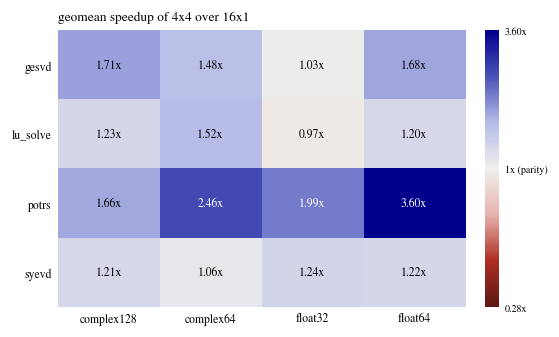

In [92]:
def plot_sweep_heatmap(summary, key="geomean", axis=None, title=None):
    """Draw routines against dtypes, shaded by speedup around parity.

    Args:
        summary: Rows produced by :func:`sweep_rows`.
        key: Row field to shade by.
        axis: Existing axis to draw on; a new figure is made when omitted.
        title: Figure title; a default is derived from ``key``.

    Returns:
        The axis that was drawn on.
    """
    if axis is None:
        _, axis = plt.subplots(figsize=(COL1 * 1.35, COL1 * 0.80), constrained_layout=True)
    routines = sorted({row["routine"] for row in summary})
    dtypes = sorted({row["dtype"] for row in summary})
    lookup = {(row["routine"], row["dtype"]): row[key] for row in summary}

    values = [math.log2(value) for value in lookup.values()]
    limit = max(0.2, max(abs(value) for value in values)) if values else 1.0
    cells = [[math.log2(lookup[(routine, dtype)]) if (routine, dtype) in lookup else math.nan
              for dtype in dtypes] for routine in routines]

    image = axis.imshow(cells, cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    for row_index, routine in enumerate(routines):
        for col_index, dtype in enumerate(dtypes):
            value = lookup.get((routine, dtype))
            if value is None:
                axis.text(col_index, row_index, "-", ha="center", va="center",
                          fontsize=FS_TICK, color=INK)
                continue
            fill = DIVERGING((math.log2(value) + limit) / (2 * limit))
            axis.text(col_index, row_index, f"{value:.2f}x", ha="center", va="center",
                      fontsize=FS_TICK, color=contrast_ink(fill))
    axis.set_xticks(range(len(dtypes)), dtypes)
    axis.set_yticks(range(len(routines)), routines)
    axis.tick_params(colors=INK, labelsize=FS_TICK, length=0)
    axis.minorticks_off()
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.set_title(title or f"{key} speedup of {CANDIDATE_GRID} over {BASELINE_GRID}",
                   color=INK, loc="left", fontsize=FS_LABEL)

    bar = axis.figure.colorbar(image, ax=axis, ticks=[-limit, 0, limit])
    bar.ax.set_yticklabels([f"{2 ** -limit:.2f}x", "1x (parity)", f"{2 ** limit:.2f}x"])
    bar.ax.tick_params(colors=INK, labelsize=FS_SMALL, length=0)
    bar.ax.minorticks_off()
    bar.outline.set_visible(False)
    return axis


plot_sweep_heatmap(sweep)
plt.show()

## 6. Coverage and failures

The two layouts do **not** cover the same matrix sizes. The planner only emits
sizes that divide the grid without padding, and `16x1` starts at `N = 4096`
while `4x4` starts at `N = 1024`; each layout also has its own memory frontier,
where cases start failing. `coverage_rows` shows what the join in §2 had to drop,
so a speedup table is never read as if it covered the whole sweep.


In [93]:
def coverage_rows(routines=None, dtypes=None, records=None):
    """Report per-grid case counts and the sizes only one grid completed.

    Args:
        routines: Routine names to include; defaults to all present.
        dtypes: Element types to include; defaults to all present.
        records: Records including failures; defaults to ``ALL_RECORDS``.

    Returns:
        One row per routine and dtype describing comparable and dropped cases.
    """
    records = ALL_RECORDS if records is None else records
    rows = []
    for routine in routines or ROUTINES:
        for dtype in dtypes or DTYPES:
            selected = [record for record in records
                        if record["routine"] == routine and record["dtype"] == dtype]
            row = {"routine": routine, "dtype": dtype}
            sizes = {}
            for grid in (BASELINE_GRID, CANDIDATE_GRID):
                passed = [record for record in selected
                          if record["grid"] == grid and record["status"] == "passed"]
                failed = [record for record in selected
                          if record["grid"] == grid and record["status"] != "passed"]
                sizes[grid] = {record["matrix_size"] for record in passed}
                row[f"{grid}_passed"] = len(passed)
                row[f"{grid}_failed"] = len(failed)
            row["common_sizes"] = len(sizes[BASELINE_GRID] & sizes[CANDIDATE_GRID])
            row[f"only_{BASELINE_GRID}"] = len(sizes[BASELINE_GRID] - sizes[CANDIDATE_GRID])
            row[f"only_{CANDIDATE_GRID}"] = len(sizes[CANDIDATE_GRID] - sizes[BASELINE_GRID])
            row["max_common_N"] = max(sizes[BASELINE_GRID] & sizes[CANDIDATE_GRID], default=None)
            rows.append(row)
    return rows


print_table(coverage_rows(), title="case coverage per routine and dtype\n")


case coverage per routine and dtype

 routine       dtype  16x1_passed  16x1_failed  4x4_passed  4x4_failed  common_sizes  only_16x1  only_4x4  max_common_N
--------  ----------  -----------  -----------  ----------  ----------  ------------  ---------  --------  ------------
   gesvd  complex128           18           20          30          35             6          0         2        65,536
   gesvd   complex64           22           22          35          36             7          0         2        98,304
   gesvd     float32           27           29          19          20             8          0         2       131,072
   gesvd     float64           23           21          35          36             7          1         2        98,304
lu_solve  complex128           40           11          61          18            13          1         7       299,008
lu_solve   complex64           51           10          74          15            17          1         7       425,984
lu_

In [94]:
def unmatched_sizes(routine, dtype):
    """List matrix sizes that only one grid completed.

    Args:
        routine: Routine name.
        dtype: Element type.

    Returns:
        Mapping of grid name to the sizes only that grid passed.
    """
    passed = {}
    for grid in (BASELINE_GRID, CANDIDATE_GRID):
        passed[grid] = {size for size, _ in case_times(routine, dtype, grid)}
    return {
        BASELINE_GRID: sorted(passed[BASELINE_GRID] - passed[CANDIDATE_GRID]),
        CANDIDATE_GRID: sorted(passed[CANDIDATE_GRID] - passed[BASELINE_GRID]),
    }


for grid, sizes in unmatched_sizes(ROUTINE, DTYPE).items():
    print(f"{ROUTINE}/{DTYPE} sizes only {grid} completed: {sizes}")


potrs/float64 sizes only 16x1 completed: [409600, 430080, 434176]
potrs/float64 sizes only 4x4 completed: [1024, 2048, 406528, 418816, 422912, 428032, 432128, 437248]


## Reading the numbers

- **One warm call per case.** `warm_median_seconds`, `warm_min_seconds`, and
  `warm_max_seconds` are equal in this sweep, so single-case ratios carry
  run-to-run noise. Trust the geometric mean over a lone point, especially at
  small `N` where the solve is short.
- **Different node allocations.** The two grids ran as separate Slurm jobs on
  different `workergpu` sets, so a cross-node fabric difference lands inside the
  ratio.
- **The join is not the whole sweep.** Sizes only one layout completed are
  excluded from every ratio — §6 lists them. A layout that fails where the other
  passes is a result too, and shows up only in the coverage table.
- **Speedup at fixed GPU count.** Both layouts use 16 GPUs, so these ratios are
  about communication shape, not scaling.


## 7. Four routines side by side

One panel per routine and precision, all drawn at **one tile size you pick**:
set `PANEL_TILE` and re-run the cell. `TILES` from §1 lists what the sweep
covered. One line per grid, at that tile alone; §8 below takes the opposite cut
and shows every tile on one grid.

Nothing is reduced over tiles here — unlike §2 and §4, no "fastest tile" is
picked for you. The panels are also *not* restricted to the sizes both grids
completed, so the right-hand end of each curve is that layout's own memory
frontier at this tile.

The figure is written to `FIGDIR` as PDF and PNG at 300 dpi, with the tile size
in the filename.

wrote /mnt/home/rwiersema/jaxmg/jaxmg_benchmark/figures/grid_speedup_four_panel_T256.pdf and .png


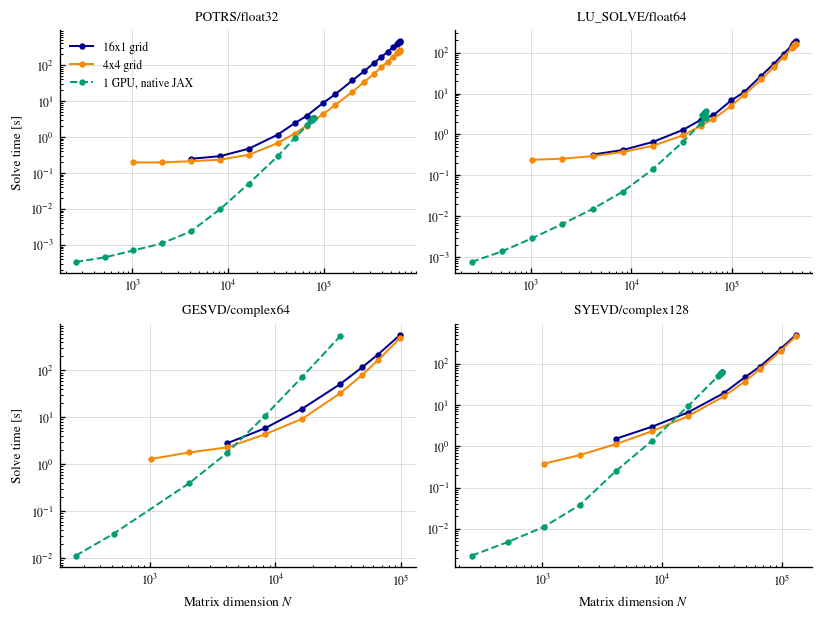

In [95]:
DTYPE_SHORT = {"float32": "float32", "float64": "float64",
               "complex64": "complex64", "complex128": "complex128"}

# One panel per routine, each at the precision that carries the most cases for
# it, so the four panels together cover both real and complex arithmetic.
PANEL_CASES = (("potrs", "float32"),
               ("lu_solve", "float64"),
               ("gesvd", "complex64"),
               ("syevd", "complex128"))

# Tile size every panel is drawn at. Set it and re-run the cell; `TILES` from
# §1 lists what the sweep covered.
PANEL_TILE = 256


def tile_times(routine, dtype, grid, tile):
    """Collect timings for a single tile size, keyed by matrix dimension.

    Args:
        routine: Routine name.
        dtype: Element type.
        grid: Process grid string.
        tile: Tile size ``T_A`` to keep.

    Returns:
        Mapping of ``matrix_size`` to seconds for that tile alone.
    """
    return {size: seconds
            for (size, case_tile), seconds in case_times(routine, dtype, grid).items()
            if case_tile == tile}


def plot_all_cases(routine, dtype, tile=None, axis=None, letter=None):
    """Plot warm solve time at one tile size, for both grids.

    The chosen tile is a solid line; every other ``(N, T_A)`` case for the same
    grid stays as a faint open marker, so the selected tile is read against the
    spread it sits in. Sizes only one grid completed are kept, which puts each
    layout's memory frontier at the end of its own curve.

    Nothing here is reduced over tiles: what is drawn is the tile you asked for.
    The single-GPU reference takes no tile, so it is drawn whatever ``tile`` is
    set to, and is simply absent until that sweep has been run.

    Args:
        routine: Routine name.
        dtype: Element type.
        tile: Tile size ``T_A`` to draw; defaults to ``PANEL_TILE``.
        axis: Existing axis to draw on; a new figure is made when omitted.
        letter: Panel letter prefixed to the title, e.g. ``"a"``.

    Returns:
        The axis that was drawn on.
    """
    tile = PANEL_TILE if tile is None else tile
    if axis is None:
        _, axis = plt.subplots(figsize=(COL1, COL1 * 0.78), constrained_layout=True)
    for grid, slot in ((BASELINE_GRID, "baseline"), (CANDIDATE_GRID, "candidate")):
        times = case_times(routine, dtype, grid)
        if not times:
            continue
        color = SERIES_COLORS[slot]
        selected = tile_times(routine, dtype, grid, tile)
        sizes = sorted(selected)
        axis.plot(sizes, [selected[size] for size in sizes], marker="o", markersize=2.8,
                  color=color, label=f"{grid} grid", zorder=3)

    # The reference every distributed curve exists to beat: one GPU, plain JAX.
    # It records one tile-less case per N, so collapsing by size is a no-op that
    # also keeps this correct if that ever changes.
    native = best_per_size(case_times(routine, dtype, NATIVE_GRID))
    if native:
        sizes = sorted(native)
        axis.plot(sizes, [native[size][1] for size in sizes], marker="o",
                  markersize=2.8, linestyle="--", color=SERIES_COLORS["native"],
                  label="1 GPU, native JAX", zorder=3)
    axis.set_xscale("log")
    axis.set_yscale("log")
    head = f"({letter}) " if letter else ""
    style_axis(axis, r"Matrix dimension $N$", "Solve time [s]",
               rf"{routine.upper()}/{DTYPE_SHORT.get(dtype, dtype)} ")
    return axis


def plot_case_panels(cases=PANEL_CASES, tile=None, save_as=None):
    """Draw a 2x2 overview at one tile size, one panel per routine and dtype.

    Args:
        cases: Four ``(routine, dtype)`` pairs, laid out row-major.
        tile: Tile size ``T_A`` to draw; defaults to ``PANEL_TILE``.
        save_as: Basename written to ``FIGDIR`` as PDF and PNG; defaults to a
            name carrying the tile size, and ``""`` skips saving.

    Returns:
        The figure that was drawn.
    """
    tile = PANEL_TILE if tile is None else tile
    save_as = f"grid_speedup_four_panel_T{tile}" if save_as is None else save_as
    figure, axes = plt.subplots(2, 2, figsize=(COL2, COL2 * 0.75),
                                constrained_layout=True)
    for axis, (routine, dtype), letter in zip(axes.flat, cases, "abcdefgh"):
        plot_all_cases(routine, dtype, tile=tile, axis=axis, letter=letter)
    # Axis labels only on the outside edge; every panel shares both quantities.
    for axis in axes[0]:
        axis.set_xlabel("")
    for axis in axes[:, 1]:
        axis.set_ylabel("")
    axes[0, 0].legend(labelcolor=INK, fontsize=FS_TICK, loc="upper left")
    if save_as:
        for suffix in ("pdf", "png"):
            figure.savefig(FIGDIR / f"{save_as}.{suffix}")
        print(f"wrote {FIGDIR / save_as}.pdf and .png")
    return figure


plot_case_panels()
plt.show()

## 8. Every tile size on one grid

The complementary cut to §7. There the tile was fixed and the grids varied; here
the grid is fixed — `TILE_PANEL_GRID`, `4x4` by default — and every `T_A` the
sweep covered is drawn as its own line.

Tile size is an *ordered* quantity, so the lines take one light-to-dark blue ramp
rather than unrelated hues: light is the smallest tile, dark the largest. Where
the lines separate, `T_A` matters; where they lie on top of each other it does
not. Each line also ends at its own memory frontier, which is why the larger
tiles stop earlier — a bigger tile rounds the local shard up further.

wrote /mnt/home/rwiersema/jaxmg/jaxmg_benchmark/figures/tile_sweep_four_panel_g4x4.pdf and .png


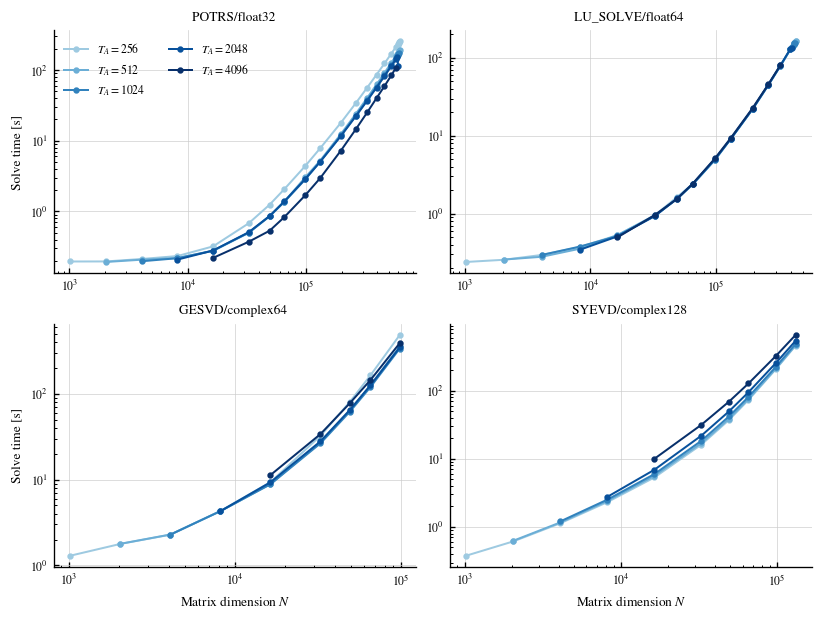

In [96]:
# Grid the tile comparison is drawn on. §7 fixes the tile and varies the grid;
# this fixes the grid and varies the tile.
TILE_PANEL_GRID = CANDIDATE_GRID


def plot_tiles_for_case(routine, dtype, grid=None, axis=None):
    """Plot warm solve time against ``N``, one line per tile size.

    Args:
        routine: Routine name.
        dtype: Element type.
        grid: Process grid string; defaults to ``TILE_PANEL_GRID``.
        axis: Existing axis to draw on; a new figure is made when omitted.

    Returns:
        The axis that was drawn on.
    """
    grid = TILE_PANEL_GRID if grid is None else grid
    if axis is None:
        _, axis = plt.subplots(figsize=(COL1, COL1 * 0.78), constrained_layout=True)
    tiles = sorted({tile for _, tile in case_times(routine, dtype, grid)})
    for index, tile in enumerate(tiles):
        selected = tile_times(routine, dtype, grid, tile)
        sizes = sorted(selected)
        axis.plot(sizes, [selected[size] for size in sizes], marker="o",
                  markersize=2.8, color=TILE_RAMP[index % len(TILE_RAMP)],
                  label=rf"$T_A={tile}$", zorder=3)
    axis.set_xscale("log")
    axis.set_yscale("log")
    style_axis(axis, r"Matrix dimension $N$", "Solve time [s]",
               rf"{routine.upper()}/{DTYPE_SHORT.get(dtype, dtype)} ")
    return axis


def plot_tile_panels(cases=PANEL_CASES, grid=None, save_as=None):
    """Draw a 2x2 overview of the tile sweep, one panel per routine and dtype.

    Args:
        cases: Four ``(routine, dtype)`` pairs, laid out row-major.
        grid: Process grid string; defaults to ``TILE_PANEL_GRID``.
        save_as: Basename written to ``FIGDIR`` as PDF and PNG; defaults to a
            name carrying the grid, and ``""`` skips saving.

    Returns:
        The figure that was drawn.
    """
    grid = TILE_PANEL_GRID if grid is None else grid
    save_as = f"tile_sweep_four_panel_g{grid}" if save_as is None else save_as
    figure, axes = plt.subplots(2, 2, figsize=(COL2, COL2 * 0.75),
                                constrained_layout=True)
    for axis, (routine, dtype) in zip(axes.flat, cases):
        plot_tiles_for_case(routine, dtype, grid=grid, axis=axis)
    # Axis labels only on the outside edge; every panel shares both quantities.
    for axis in axes[0]:
        axis.set_xlabel("")
    for axis in axes[:, 1]:
        axis.set_ylabel("")
    axes[0, 0].legend(labelcolor=INK, fontsize=FS_TICK, loc="upper left", ncols=2)
    if save_as:
        for suffix in ("pdf", "png"):
            figure.savefig(FIGDIR / f"{save_as}.{suffix}")
        print(f"wrote {FIGDIR / save_as}.pdf and .png")
    return figure


plot_tile_panels()
plt.show()